# Stage 5 — Model Evaluation

Notebook นี้เป็น canonical evaluation ของ ML lifecycle: เลือก threshold จาก validation เท่านั้น แล้วรายงานผลบน test พร้อม slice และ platform-pair metrics

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (average_precision_score, confusion_matrix,
                             precision_score, recall_score, f1_score)

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'pyproject.toml').exists())
SRC = ROOT / 'src'
if str(SRC) not in sys.path: sys.path.insert(0, str(SRC))
from identity_resolution.stages import evaluate
print('Project root:', ROOT)

Matplotlib is building the font cache; this may take a moment.


Project root: /Users/thawaree.kha/Project-for-Work


## 1. Load and validate the scored dataset

In [2]:
DATA_PATH = ROOT / 'pub_multi' / 'data' / 'train_all.parquet'
required = {'split_name', 'label', 'probability', *evaluate.NAME_COLS, *evaluate.BIO_COLS,
            'platform_a', 'platform_b'}
df = pd.read_parquet(DATA_PATH)
missing = sorted(required - set(df.columns))
assert not missing, f'Missing columns: {missing}'
assert set(df['split_name'].unique()) >= {'train', 'val', 'test'}
assert df['label'].isin([0, 1]).all()
assert df['probability'].between(0, 1).all()
display(pd.DataFrame({
    'rows': df.groupby('split_name').size(),
    'positives': df.groupby('split_name')['label'].sum(),
    'positive_rate': df.groupby('split_name')['label'].mean(),
}).loc[['train', 'val', 'test']])
print('Shape:', df.shape, '| Features/columns:', len(df.columns))

,rows,positives,positive_rate
split_name,,,
train,41803,20470,0.489678
val,8580,4386,0.511189
test,8313,4387,0.527728


Shape: (58696, 57) | Features/columns: 57


## 2. Select threshold on validation only
Test labels are not used for threshold selection.

,validation_best
threshold,0.3500
precision,0.9552
recall,0.9136
f1,0.9339
FN,379.0000
FP,188.0000


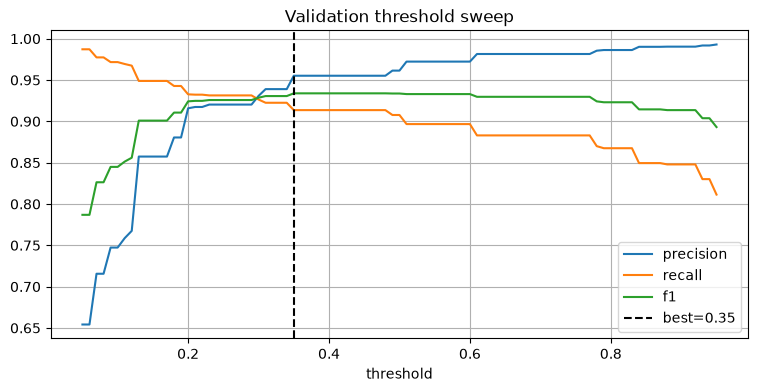

In [3]:
BEST_THRESHOLD, sweep = evaluate.select_threshold(df, split='val', score_col='probability')
best = sweep.sort_values(['f1', 'precision'], ascending=False).iloc[0]
display(best.to_frame('validation_best'))
ax = sweep.plot(x='threshold', y=['precision', 'recall', 'f1'], figsize=(9, 4), grid=True)
ax.axvline(BEST_THRESHOLD, color='black', linestyle='--', label=f'best={BEST_THRESHOLD:.2f}')
ax.legend(); plt.title('Validation threshold sweep'); plt.show()

## 3. Final test metrics at the validation-selected threshold

In [4]:
test = df[df.split_name == 'test'].copy()
y_test = test.label.to_numpy()
p_test = test.probability.to_numpy()
pred_test = (p_test >= BEST_THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred_test, labels=[0, 1]).ravel()
test_metrics = {
    'threshold_selected_on_validation': BEST_THRESHOLD,
    'average_precision': float(average_precision_score(y_test, p_test)),
    'precision': float(precision_score(y_test, pred_test, zero_division=0)),
    'recall': float(recall_score(y_test, pred_test, zero_division=0)),
    'f1': float(f1_score(y_test, pred_test, zero_division=0)),
    'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
}
display(pd.Series(test_metrics, name='test'))
display(pd.DataFrame([[tn, fp], [fn, tp]],
                     index=['actual_0', 'actual_1'],
                     columns=['pred_0', 'pred_1']))

threshold_selected_on_validation       0.350000
average_precision                      0.978928
precision                              0.950661
recall                                 0.917939
f1                                     0.934014
tn                                  3717.000000
fp                                   209.000000
fn                                   360.000000
tp                                  4027.000000
Name: test, dtype: float64

,pred_0,pred_1
actual_0,3717,209
actual_1,360,4027


## 4. Slice-aware and platform-pair evaluation

In [5]:
report = evaluate.full_report(df, score_col='probability',
                              thr=BEST_THRESHOLD, split='test')
display(pd.DataFrame(report['by_slice']).T)
display(pd.DataFrame(report['by_platform_pair']).T.sort_index())

,n_pos,recall,FN
EASY,4234.0,0.9433,240.0
MID,148.0,0.2230,115.0
HARD,5.0,0.0000,5.0


,precision,recall,f1,FN,FP,n_pos
googleplus x instagram,0.9439,0.9138,0.9286,84.0,53.0,975.0
googleplus x twitter,0.9548,0.8936,0.9232,191.0,76.0,1795.0
instagram x twitter,0.9504,0.9474,0.9489,85.0,80.0,1617.0


## 5. Save the reproducible evaluation artifact

In [6]:
OUTPUT_DIR = ROOT / 'artifacts' / 'evaluation'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
summary = {
    'data_path': str(DATA_PATH.relative_to(ROOT)),
    'selection_rule': 'maximize validation F1; precision breaks ties',
    'validation_best': {k: float(best[k]) for k in ['threshold', 'precision', 'recall', 'f1']},
    'test': test_metrics,
    'slice_report': report['by_slice'],
    'platform_pair_report': report['by_platform_pair'],
}
output_path = OUTPUT_DIR / 'notebook_model_evaluation.json'
output_path.write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding='utf-8')
print('Saved:', output_path)
print('EVALUATE STAGE: PASS')

Saved: /Users/thawaree.kha/Project-for-Work/artifacts/evaluation/notebook_model_evaluation.json
EVALUATE STAGE: PASS
